# 06 Targeting decision: whom should the budget reach?

**Project question.** With a limited marketing budget, which customers should receive an SMS so that it creates the most additional purchases?

**This notebook.** Notebooks 04 and 05 showed that the SMS effect differs between clients and that an uplift model can rank them. Here that ranking becomes a decision. Four policies are compared on the test set, which no model has seen: contact everyone, contact at random, contact the clients most likely to buy, and contact the clients with the highest predicted uplift. Results are given as extra purchases and as profit for any ratio of contact cost to purchase margin.

**Summary.** On customers the model never saw, sending the SMS to the 10% it ranks highest brings about 75 extra buyers per 1,000 messages, against 33 when sending at random and 10 when sending to the most loyal buyers. Whether targeting also pays depends on what a message costs compared with what an extra purchase earns: when messages are cheap, sending to almost everyone is fine, but once the cost passes about 3% of the margin, mass sending loses money and targeting keeps the campaign profitable. A follow-up test with roughly 9,000 to 50,000 customers per group could confirm this in a new campaign.

**Research question.** For a given budget, which targeting policy creates the most extra purchases and profit, and how much does the answer depend on cost and margin?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from x5uplift import plotting as P
from x5uplift.config import PROPENSITY_PATH, SEED, UPLIFT_PATH, SEGMENTS_PATH, DEMO_DATA_DIR
from x5uplift.experiment import diff_in_means
from x5uplift.modeling import load_experiment
from x5uplift.policy import bootstrap_curves, budget_index, interval, per_sms, profit
from x5uplift.uplift import FRACTIONS, ranking, uplift_curve

pd.set_option("display.width", 140)
P.set_style()

## 1. Data: the untouched test set

The 30% test set (notebook 01) was used for no modelling choice. Its purchase probabilities come from the notebook 03 model and its uplift predictions from the X-learner fitted on all training folds (notebook 05). Both use only information from before the SMS, so they should be balanced between the SMS and control groups.

In [2]:
exp = (
    load_experiment()
    .merge(pd.read_parquet(PROPENSITY_PATH), on="client_id", validate="one_to_one")
    .merge(pd.read_parquet(UPLIFT_PATH), on="client_id", validate="one_to_one")
)
test = exp[exp["fold"] < 0].reset_index(drop=True)
t, y = test["treatment_flg"].to_numpy(), test["target"].to_numpy()

display(test.groupby("treatment_flg").agg(
    clients=("target", "size"), purchase_rate=("target", "mean"),
    mean_p_buy_without_sms=("p_buy_without_sms", "mean"), mean_predicted_uplift=("uplift", "mean")).round(4))

ate = diff_in_means(y, t)
print(f"Effect of the SMS in the test set: {100 * ate['effect']:.2f} points [{100 * ate['ci_low']:.2f}, {100 * ate['ci_high']:.2f}]")

,clients,purchase_rate,mean_p_buy_without_sms,mean_predicted_uplift
treatment_flg,,,,
0,30017,0.6033,0.6031,0.0330
1,29995,0.6365,0.6042,0.0328


Effect of the SMS in the test set: 3.32 points [2.55, 4.10]


The test set is balanced on both scores, and the SMS effect there is 3.32 points [2.55, 4.10], the same as in the full experiment. (Purchase rates match the full experiment exactly because the split was stratified by group and outcome.)

## 2. Extra purchases by policy and budget

Each policy contacts the top share of its ranking:

* **Uplift:** highest predicted uplift first (X-learner, notebook 05).
* **Purchase probability:** clients most likely to buy first (notebook 03), a common default.
* **Random:** no targeting; its expected result is the share contacted times the average effect.
* **Everyone:** the 100% end of every curve.

Because the SMS was assigned at random, the extra purchases a policy creates can be estimated from the test set: inside the contacted share, the SMS purchase rate minus the control purchase rate. Intervals come from 500 bootstrap resamples shared by all policies, so differences between policies are paired.

In [3]:
scores = {"Uplift (X-learner)": test["uplift"].to_numpy(),
          "Purchase probability": test["p_buy_without_sms"].to_numpy()}
curves = bootstrap_curves(y, t, scores, n_boot=500)

def fmt(df):
    """Estimate [95% interval], one row per policy, one column per budget."""
    r = lambda v: f"{0 if abs(v) < 0.5 else v:.0f}"
    text = df["estimate"].map(r) + " [" + df["ci_low"].map(r) + ", " + df["ci_high"].map(r) + "]"
    return text.set_axis(pd.MultiIndex.from_frame(df[["policy", "budget"]])).unstack("budget").rename(columns="{:.0%}".format)

budgets = [0.1, 0.2, 0.3, 0.5, 1.0]
fmt(per_sms(curves, budgets))       # extra purchases per 1,000 messages

budget,10%,20%,30%,50%,100%
policy,,,,,
Purchase probability,"10 [0, 20]","12 [3, 21]","17 [9, 26]","24 [16, 32]","33 [26, 41]"
Random,"33 [26, 41]","33 [26, 41]","33 [26, 41]","33 [26, 41]","33 [26, 41]"
Uplift (X-learner),"75 [50, 100]","69 [52, 87]","59 [45, 74]","49 [38, 61]","33 [26, 41]"


In [4]:
display(fmt(per_sms(curves, [0.1, 0.2, 0.3], reference="Random")))
fmt(per_sms(curves, [0.1, 0.2, 0.3], reference="Purchase probability"))

budget,10%,20%,30%
policy,,,
Purchase probability,"-23 [-36, -12]","-21 [-31, -11]","-16 [-25, -6]"
Uplift (X-learner),"41 [18, 66]","36 [21, 50]","26 [14, 37]"


budget,10%,20%,30%
policy,,,
Random,"23 [12, 36]","21 [11, 31]","16 [6, 25]"
Uplift (X-learner),"65 [39, 94]","57 [37, 78]","42 [25, 58]"


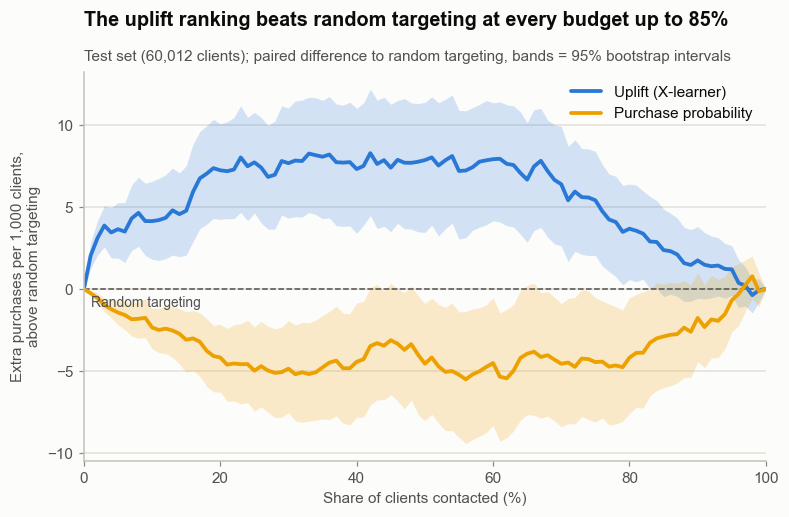

In [5]:
pct = 100 * FRACTIONS
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axhline(0, color=P.INK_2, linewidth=1, linestyle="--")
ax.text(1, -0.4, "Random targeting", ha="left", va="top", fontsize=9, color=P.INK_2)
gap = {}
for name, color in [("Uplift (X-learner)", P.BLUE), ("Purchase probability", P.YELLOW)]:
    gap[name] = interval(1000 * (curves[name] - curves["Random"]))      # paired difference to random
    ax.fill_between(pct, gap[name]["ci_low"], gap[name]["ci_high"], color=color, alpha=0.2, linewidth=0)
    ax.plot(pct, gap[name]["estimate"], color=color, linewidth=2.5, label=name)
ax.set(xlim=(0, 100), xlabel="Share of clients contacted (%)",
       ylabel="Extra purchases per 1,000 clients,\nabove random targeting")
ax.legend(loc="upper right")
above = gap["Uplift (X-learner)"]["ci_low"][1:-1] > 0                 # interval above zero, 1% to 99%
limit = FRACTIONS[1:-1][np.argmin(above)] if not above.all() else 1.0
P.titles(ax, f"The uplift ranking beats random targeting at every budget up to {limit:.0%}",
         "Test set (60,012 clients); paired difference to random targeting, bands = 95% bootstrap intervals")
P.save(fig, "06_policy_gap")

On data no model has seen, the uplift ranking creates 75 extra purchases per 1,000 messages at a 10% budget [50, 100], against 33 for random targeting and 10 for contacting the likeliest buyers. Its paired advantage over random targeting is 41 [18, 66] at 10%, 36 [21, 50] at 20% and 26 [14, 37] at 30%, and stays above zero up to about 85% of clients. Contacting the likeliest buyers is worse than random at every budget (−23 [−36, −12] at 10%). The training fold estimate of notebook 05 (about 100 at 10%) was optimistic, as expected after choosing the best of five models on the same data.

## 4. From extra purchases to profit

Profit = extra purchases × margin of one purchase − messages sent × cost of one message. Neither the currency nor the margin is in the data, so everything is expressed with one ratio: **r = cost of one SMS / margin of one extra purchase**, and profit is counted in margins of one purchase. Contacting a client pays only if the SMS raises their purchase probability by more than r. With the average effect of 3.3 points, contacting everyone breaks even at r = 0.033.

The example uses **r = 0.05**: the SMS costs 5% of the margin of one purchase, so contacting everyone loses money. Section 5 varies r.

Each policy's budget is the one that maximizes profit on the **training folds** (using the out of fold predictions of notebook 05); its profit is then measured on the test set. Choosing the budget on the test set itself would flatter the result. Without targeting, the choice is between contacting everyone and contacting no one.

In [6]:
R = 0.05                                                 # cost of one SMS / margin of one extra purchase
cols = {"Uplift (X-learner)": "uplift", "Purchase probability": "p_buy_without_sms"}
train = exp[exp["fold"] >= 0]
t_tr, y_tr = train["treatment_flg"].to_numpy(), train["target"].to_numpy()

def chosen_budget(cost_ratio):
    """Budget that maximizes profit on the training folds, per policy (chosen without the test set)."""
    out = {name: FRACTIONS[np.argmax(profit(uplift_curve(y_tr, t_tr, ranking(train[col].to_numpy())), cost_ratio))]
           for name, col in cols.items()}
    out["No targeting"] = 1.0 if y_tr[t_tr == 1].mean() - y_tr[t_tr == 0].mean() > cost_ratio else 0.0   # everyone or no one
    return out

def test_profit(cost_ratio, budgets):
    """Bootstrap draws of the test set profit per 1,000 clients at each policy's budget, in margins of one purchase."""
    return {name: 1000 * (curves["Random" if name == "No targeting" else name][:, budget_index(k)] - cost_ratio * k)
            for name, k in budgets.items()}

k_star = chosen_budget(R)
draws = test_profit(R, k_star)
rows = {name: {"budget": f"{k_star[name]:.0%}", **interval(d)} for name, d in draws.items()}
rows["Uplift minus no targeting"] = {"budget": "", **interval(draws["Uplift (X-learner)"] - draws["No targeting"])}
print(f"Contacting everyone at r = {R}: {1000 * (curves['Random'][0, -1] - R):.1f} per 1,000 clients")
pd.DataFrame(rows).T

Contacting everyone at r = 0.05: -16.8 per 1,000 clients


,budget,estimate,ci_low,ci_high
Uplift (X-learner),9%,2.629164,0.292086,5.155018
Purchase probability,0%,0.0,0.0,0.0
No targeting,0%,0.0,0.0,0.0
Uplift minus no targeting,,2.629164,0.292086,5.155018


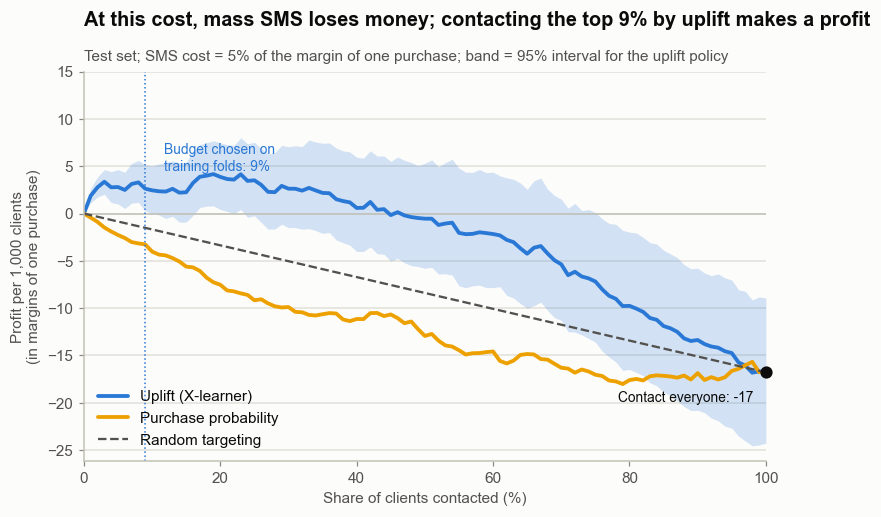

In [7]:
pct = 100 * FRACTIONS
up = interval(1000 * (curves["Uplift (X-learner)"] - R * FRACTIONS))
k = k_star["Uplift (X-learner)"]
everyone = 1000 * (curves["Random"][0, -1] - R)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.axhline(0, color=P.AXIS, linewidth=1)
ax.fill_between(pct, up["ci_low"], up["ci_high"], color=P.BLUE, alpha=0.2, linewidth=0)
ax.plot(pct, up["estimate"], color=P.BLUE, linewidth=2.5, label="Uplift (X-learner)")
ax.plot(pct, 1000 * (curves["Purchase probability"][0] - R * FRACTIONS), color=P.YELLOW, linewidth=2.5, label="Purchase probability")
ax.plot(pct, 1000 * (curves["Random"][0] - R * FRACTIONS), color=P.INK_2, linewidth=1.5, linestyle="--", label="Random targeting")
ax.axvline(100 * k, color=P.BLUE, linewidth=1, linestyle=":")
ax.annotate(f"Budget chosen on\ntraining folds: {k:.0%}", (100 * k, up["estimate"][budget_index(k)]),
            xytext=(12, 12), textcoords="offset points", fontsize=9, color=P.BLUE)
ax.plot(100, everyone, "o", color=P.INK, markersize=7, zorder=5, clip_on=False)
ax.annotate(f"Contact everyone: {everyone:.0f}", (100, everyone), xytext=(-8, -12),
            textcoords="offset points", ha="right", va="top", fontsize=9)
ax.set(xlim=(0, 100), xlabel="Share of clients contacted (%)", ylabel="Profit per 1,000 clients\n(in margins of one purchase)")
ax.legend(loc="lower left")
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.15 * (hi - lo))
P.titles(ax, f"At this cost, mass SMS loses money; contacting the top {k:.0%} by uplift makes a profit",
         f"Test set; SMS cost = {R:.0%} of the margin of one purchase; band = 95% interval for the uplift policy")
P.save(fig, "06_profit")

At r = 0.05, contacting everyone loses 16.8 margins per 1,000 clients, and on the training folds neither contacting everyone nor contacting the likeliest buyers pays, so both choose to contact no one. The uplift policy contacts the top 9% and earns 2.6 margins per 1,000 clients [0.3, 5.2]: its 90 messages cost 4.5 margins and bring about 7.1, a return of about 1.6 per unit spent. The profit is small and its interval comes close to zero; the clearer contrast is with contacting everyone at the same cost.

## 5. How much does the answer depend on cost and margin?

The cost ratio r is unknown, so the whole decision (budget chosen on the training folds, profit measured on the test set) is repeated for r from 0 to 12%.

In [8]:
ratios = np.round(np.arange(0, 0.1201, 0.005), 3)
sens = []
for r in ratios:
    ks = chosen_budget(r)
    d = test_profit(r, ks)
    d["Uplift minus no targeting"] = d["Uplift (X-learner)"] - d["No targeting"]
    for name, dr in d.items():
        sens.append({"cost_ratio": r, "policy": name, "budget": ks.get(name, np.nan), **interval(dr)})
sens = pd.DataFrame(sens)

cell = lambda row: f"{row['estimate']:.1f} [{row['ci_low']:.1f}, {row['ci_high']:.1f}]"
show = sens[sens["cost_ratio"].isin([0.01, 0.02, 0.03, 0.04, 0.05, 0.08, 0.1])]
profits = show.assign(profit=show.apply(cell, axis=1)).pivot(index="cost_ratio", columns="policy", values="profit")
chosen = show.dropna(subset=["budget"]).pivot(index="cost_ratio", columns="policy", values="budget").map("{:.0%}".format)
profits.join(chosen, rsuffix=" (budget)")

policy,No targeting,Purchase probability,Uplift (X-learner),Uplift minus no targeting,No targeting (budget),Purchase probability (budget),Uplift (X-learner) (budget)
cost_ratio,,,,,,,
0.01,"23.2 [15.7, 31.1]","23.2 [15.7, 31.1]","23.3 [15.3, 31.0]","0.0 [-1.6, 1.4]",100%,100%,95%
0.02,"13.2 [5.7, 21.1]","13.2 [5.7, 21.1]","14.2 [7.5, 22.0]","1.0 [-2.4, 3.9]",100%,100%,80%
0.03,"3.2 [-4.3, 11.1]","3.2 [-4.3, 11.1]","9.8 [4.3, 16.5]","6.6 [1.1, 12.0]",100%,100%,54%
0.04,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","5.0 [1.1, 9.0]","5.0 [1.1, 9.0]",0%,0%,27%
0.05,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","2.6 [0.3, 5.2]","2.6 [0.3, 5.2]",0%,0%,9%
0.08,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","1.3 [-0.5, 3.1]","1.3 [-0.5, 3.1]",0%,0%,5%
0.10,"0.0 [0.0, 0.0]","0.0 [0.0, 0.0]","1.8 [0.8, 2.9]","1.8 [0.8, 2.9]",0%,0%,2%


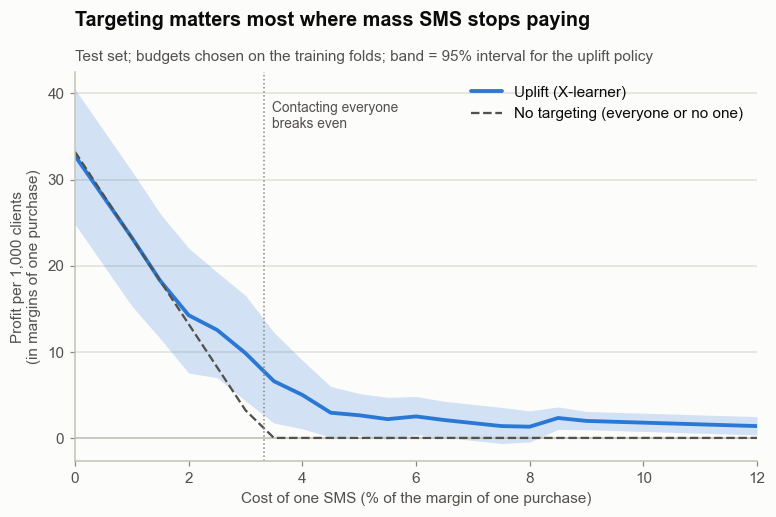

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.6))
x = 100 * ratios
ax.axhline(0, color=P.AXIS, linewidth=1)
for name, color, style in [("Uplift (X-learner)", P.BLUE, "-"), ("No targeting", P.INK_2, "--")]:
    s = sens[sens["policy"] == name]
    if name == "Uplift (X-learner)":
        ax.fill_between(x, s["ci_low"], s["ci_high"], color=color, alpha=0.2, linewidth=0)
    ax.plot(x, s["estimate"], color=color, linewidth=2.5 if style == "-" else 1.5, linestyle=style,
            label="No targeting (everyone or no one)" if name == "No targeting" else name)
ate_tr = 100 * (y_tr[t_tr == 1].mean() - y_tr[t_tr == 0].mean())
ax.axvline(ate_tr, color=P.MUTED, linewidth=1, linestyle=":")
ax.text(ate_tr + 0.15, ax.get_ylim()[1] * 0.92, "Contacting everyone\nbreaks even", fontsize=9, color=P.INK_2, va="top")
ax.set(xlim=(0, x.max()), xlabel="Cost of one SMS (% of the margin of one purchase)",
       ylabel="Profit per 1,000 clients\n(in margins of one purchase)")
ax.legend(loc="upper right")
gain = sens[sens["policy"] == "Uplift minus no targeting"]
wins = gain.loc[gain["ci_low"] > 0, "cost_ratio"]
P.titles(ax, "Targeting matters most where mass SMS stops paying",
         "Test set; budgets chosen on the training folds; band = 95% interval for the uplift policy")
P.save(fig, "06_profit_sensitivity")

Below a cost of about 2% of the margin, contacting everyone already pays and the uplift policy contacts 80% to 95% of clients, so the two hardly differ (gain 0.0 [−1.6, 1.4] at 1%). The value of targeting is largest around the cost where mass SMS stops paying: at 3% the uplift policy contacts 54% and earns 6.6 more margins per 1,000 clients than contacting everyone [1.1, 12.0]; at 4% and 5% it earns 5.0 [1.1, 9.0] and 2.6 [0.3, 5.2] while the best untargeted choice is to contact no one. At high costs it contacts only the top 2% to 5% and the gain is small (1.3 [−0.5, 3.1] at 8%). Contacting the likeliest buyers never beats no targeting: on the training folds it always ends at everyone or no one.

## 6. Whom does the uplift policy contact?

An aggregated profile of the clients the uplift policy contacts at different budgets on the test set, from information before the SMS. The 100% column is the whole test set. No client level data is shown.

In [10]:
segment = pd.read_parquet(SEGMENTS_PATH).set_index("client_id").loc[test["client_id"], "segment_name"].to_numpy()
rank_share = np.empty(len(test))
rank_share[ranking(test["uplift"].to_numpy())] = np.arange(1, len(test) + 1) / len(test)   # 0.01 = top 1% by uplift

def audience(budget):
    """Aggregated profile of the clients the uplift policy contacts at a budget (no client level data)."""
    a = test[rank_share <= budget]
    return {"clients": len(a), "predicted uplift (points)": 100 * a["uplift"].mean(),
            "purchase probability without SMS (%)": 100 * a["p_buy_without_sms"].mean(),
            "median age": a["age"].median(), "median visits, last 30 days": a["n_baskets_recent"].median(),
            "median days since card issue": a["days_since_card_issue"].median(),
            "redeemed points before (%)": 100 * a["redeemed_before_cutoff"].mean()}

shown = [0.1, 0.3, 0.5, 1.0]
display(pd.DataFrame({f"{b:.0%}": audience(b) for b in shown}).round(1))
pd.DataFrame({f"{b:.0%}": pd.Series(segment[rank_share <= b]).value_counts(normalize=True) * 100
              for b in shown}).round(1).sort_values("10%", ascending=False)

,10%,30%,50%,100%
clients,6001.0,18003.0,30006.0,60012.0
predicted uplift (points),8.7,5.9,4.8,3.3
purchase probability without SMS (%),42.7,47.1,51.0,60.4
median age,57.0,54.0,52.0,45.0
"median visits, last 30 days",2.0,3.0,3.0,5.0
median days since card issue,261.0,383.0,436.0,486.0
redeemed points before (%),74.4,75.1,75.8,79.9


,10%,30%,50%,100%
Regular small baskets,37.7,35.1,32.8,23.6
Occasional shoppers,26.1,23.9,21.5,16.3
Point redeemers,18.7,11.4,8.5,5.2
Big basket shoppers,7.8,15.4,18.5,22.8
Alcohol and own brand buyers,6.2,7.1,7.2,6.6
Daily top-up shoppers,2.8,6.1,10.5,24.3
Express point collectors,0.7,0.9,1.0,1.2


At a 10% budget the uplift policy contacts clients who are older (median 57 against 45), visit less (2 against 5 times in 30 days), have newer cards (261 against 486 days) and are less likely to buy anyway (43% against 60%). Point redeemers make up 19% of them against 5% of all clients, daily top-up shoppers 3% against 24%. As the budget grows, the profile moves steadily towards the whole base.

## 7. Designing a follow-up A/B test

These results come from one campaign in 2019. Before adopting the policy, a company would confirm it in a new campaign. Two designs, sized here with the test set estimates (5% significance, 80% power, normal approximation):

* **A. Policy against policy.** Clients are split at random into two arms; one arm applies the uplift policy, the other contacts a random share of the same size, and the purchase rates of the whole arms are compared. Only the contacted share differs between arms, so the rest adds noise.
* **B. Effect inside the targeted group.** Two groups, each split at random into SMS and no SMS: the top of the uplift ranking, and a random sample of all clients. The SMS effect in the first is compared with the effect in the second. Only clients who matter for the comparison are in the test.

In [11]:
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
ate_test = curves["Random"][0, -1]
rows = []
for b in [0.1, 0.2, 0.3]:
    i = budget_index(b)
    in_top = rank_share <= b
    gap = curves["Uplift (X-learner)"][0, i] - curves["Random"][0, i]     # difference between whole arms
    effect_top = curves["Uplift (X-learner)"][0, i] / b                     # SMS effect inside the top share
    rows.append({
        "budget": f"{b:.0%}",
        "effect in top share (points)": 100 * effect_top,
        "effect in all clients (points)": 100 * ate_test,
        "A: clients per arm": 2 * z**2 * y.var() / gap**2,
        "B: clients per group": 4 * z**2 * (y[in_top].var() + y.var()) / (effect_top - ate_test) ** 2,
    })
pd.DataFrame(rows).set_index("budget").round(1).astype({"A: clients per arm": int, "B: clients per group": int})

,effect in top share (points),effect in all clients (points),A: clients per arm,B: clients per group
budget,,,,
10%,7.5,3.3,216206,8906
20%,6.9,3.3,70722,11659
30%,5.9,3.3,62961,23355


Design B needs far fewer clients: about 8,900 per group at a 10% budget, against 216,000 per arm for design A, whose two arms together would exceed X5's entire base of 400,162 clients. As the budget grows the two designs converge (63,000 against 23,000 at 30%). These sizes assume the effects found on the test set. If the effect in the top 10% were at the low end of its interval (5.0 instead of 7.5 points), design B would need about six times as many clients, so a cautious plan would size it for roughly 50,000 clients per group. The recommended follow-up is design B at a 10% budget: it tests whether the SMS works better in the targeted group than on average, and whether its effect there exceeds the cost ratio.

## 8. Outputs for the demo

The Streamlit demo trains nothing; it reads two aggregated tables written here. `policy_curves.csv` holds, for 101 budget shares, the extra purchases per client of each policy on the test set with 95% intervals, plus the training fold curves used to suggest a budget. `audience.csv` holds the profile of the clients the uplift policy contacts, in 5% steps. Neither contains client level data; the smallest group has about 3,000 clients.

In [12]:
DEMO_DATA_DIR.mkdir(parents=True, exist_ok=True)
names = {"uplift": "Uplift (X-learner)", "purchase_probability": "Purchase probability", "random": "Random"}
curves_out = pd.DataFrame({"share_contacted": FRACTIONS})
for short, name in names.items():
    ci = interval(curves[name])
    curves_out[short], curves_out[f"{short}_low"], curves_out[f"{short}_high"] = ci["estimate"], ci["ci_low"], ci["ci_high"]
for short, col in [("uplift", "uplift"), ("purchase_probability", "p_buy_without_sms")]:   # used to suggest a budget
    curves_out[f"{short}_train"] = uplift_curve(y_tr, t_tr, ranking(train[col].to_numpy()))
curves_out["random_train"] = FRACTIONS * (y_tr[t_tr == 1].mean() - y_tr[t_tr == 0].mean())

steps = np.round(np.arange(0.05, 1.001, 0.05), 2)
segments_out = (pd.DataFrame({b: pd.Series(segment[rank_share <= b]).value_counts(normalize=True) for b in steps})
                  .T.fillna(0).rename_axis("budget").reset_index())
aud = pd.DataFrame([{"budget": b, **audience(b)} for b in steps]).merge(segments_out, on="budget")
assert aud["clients"].min() >= 500                       # aggregates only, never small groups

curves_out.round(6).to_csv(DEMO_DATA_DIR / "policy_curves.csv", index=False)
aud.round(4).to_csv(DEMO_DATA_DIR / "audience.csv", index=False)
print(curves_out.shape, aud.shape)
aud.head(3)

(101, 13) (20, 15)


,budget,clients,predicted uplift (points),purchase probability without SMS (%),median age,"median visits, last 30 days",median days since card issue,redeemed points before (%),Alcohol and own brand buyers,Big basket shoppers,Daily top-up shoppers,Express point collectors,Occasional shoppers,Point redeemers,Regular small baskets
0,0.05,3000,10.896033,39.862376,58.0,2.0,194.5,72.533333,0.049333,0.033333,0.018667,0.006000,0.289000,0.250000,0.353667
1,0.10,6001,8.675441,42.696031,57.0,2.0,261.0,74.404266,0.061656,0.078487,0.027829,0.007332,0.260957,0.186802,0.376937
2,0.15,9001,7.559726,44.198350,56.0,3.0,322.0,75.380513,0.065104,0.105766,0.033107,0.007110,0.252527,0.157649,0.378736


## Conclusion

**Answer.** With a fixed budget, the clients to contact are those with the highest predicted uplift. On the test set, which no model choice used, contacting the top 10% this way creates 75 extra purchases per 1,000 messages [50, 100], against 33 for random targeting and 10 for the likeliest buyers; the paired advantage over random targeting is 41 [18, 66] at 10%, 36 [21, 50] at 20% and 26 [14, 37] at 30%. Whether targeting also pays depends on the ratio of contact cost to purchase margin: it adds little when messages are cheap enough to send to everyone, and matters most where mass sending stops paying, around 3% to 5% of the margin (6.6 [1.1, 12.0] more margins per 1,000 clients at 3%, 2.6 [0.3, 5.2] at 5%).

**What we learned**
* Contacting the likeliest buyers is worse than random targeting at every budget (−23 [−36, −12] per 1,000 messages at 10%) and never beats the best untargeted choice at any cost.
* The training fold estimate of notebook 05 (about 100 per 1,000 messages at 10%) was optimistic; the unbiased test set figure is 75.
* At a cost of 5% of the margin, contacting everyone loses 16.8 margins per 1,000 clients, while contacting the top 9% by uplift earns 2.6, about 1.6 returned per unit spent.
* The contacted clients are older, newer to the card, visit less and are less likely to buy anyway; point redeemers are overrepresented.
* A follow-up test that measures the effect inside the targeted group needs about 9,000 clients per group at a 10% budget (about 50,000 under a cautious assumption), while a test of policy against policy would need more clients than X5 has.

**What remains open**
* The margin of an extra purchase is an assumption: the data cannot tell whether the SMS creates new purchases or moves planned ones earlier, or how much they are worth.
* The test set has 60,012 clients, so intervals are wide; at 5% the profit interval comes close to zero.
* The results come from one campaign in 2019, in one Russian grocery chain, for recently active clients. A ranking learned on one campaign may weaken over time, which is what the follow-up test would check.

**Next step.** Notebook 07 measures which feature groups the uplift model relies on (ablation), where its ranking works and fails (error analysis), and optionally whether the methods behave the same way on a second randomized dataset (Criteo).